<a href="https://colab.research.google.com/github/MrSiwan0909/silent-diabetes/blob/main/silent_diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Silent Diabetes: a no-blood-test screening tool

**Track:** AI + Health. Veritas AI International High School Hackathon 2026

**The idea:** about 64% of adults with diabetes in the UAE don't know they have it (IDF estimate). A pharmacist or a mall health-booth volunteer could ask about 10 simple questions (no blood test) and send higher-risk people to a doctor for an **HbA1c** blood test.

**This notebook:** loads the data, builds two baselines (including the American Diabetes Association's risk test), trains two models, picks a screening threshold, checks fairness, explains predictions, and saves the model for the app.

> This project is a prototype and is not medical advice.

## 0. Setup: install and import packages

Google Colab already has pandas, scikit-learn and matplotlib. We only need to install:
- `ucimlrepo`: downloads datasets from the UCI Machine Learning Repository
- `gradio`: builds the simple web app at the end

In [ ]:
# Install the two packages Colab doesn't have (-q = quiet, less text)
!pip install -q ucimlrepo gradio

In [ ]:
import pandas as pd               # tables of data
import numpy as np                # maths on arrays of numbers
import matplotlib.pyplot as plt   # charts

# One fixed 'random seed' so we get the same results every time we run the notebook
RANDOM_SEED = 42

print('Packages loaded.')

Packages loaded.


## 1. Load the data

**Dataset:** CDC Diabetes Health Indicators. These are answers from the 2015 BRFSS phone survey of **253,680 US adults**. Each row is one person.

We download it fresh every time (it is **not** stored in our GitHub repo). If the `ucimlrepo` package fails, we read the same CSV file directly from the UCI website instead.

In [ ]:
try:
    from ucimlrepo import fetch_ucirepo
    cdc = fetch_ucirepo(id=891)
    # cdc.data.features = the answers, cdc.data.targets = diabetes yes/no
    df = pd.concat([cdc.data.features, cdc.data.targets], axis=1)
    variable_info = cdc.variables   # official description of every column
    print('Loaded with ucimlrepo.')
except Exception as error:
    print('ucimlrepo failed:', error)
    print('Reading the CSV straight from the UCI website instead...')
    df = pd.read_csv('https://archive.ics.uci.edu/static/public/891/data.csv')
    df = df.drop(columns=['ID'])   # ID is just a row number, not useful
    variable_info = None

print('Rows (people):', len(df))
print('Columns:', len(df.columns))
df.head()

Loaded with ucimlrepo.
Rows (people): 253680
Columns: 22


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


### 1a. Choose only the questions a pharmacist can ask

The dataset has 21 questions. We keep only the ones you can answer **without a lab test** and that are quick to ask at a counter:

| Column | Question we would ask | Codes in the data |
|---|---|---|
| `Age` | How old are you? | **Groups, not years:** 1 = 18-24, 2 = 25-29, ... 5-year steps ... 12 = 75-79, 13 = 80+ |
| `Sex` | Sex | 0 = female, 1 = male |
| `BMI` | Height and weight (we calculate BMI) | a number, e.g. 27 |
| `HighBP` | Has a doctor ever told you that you have high blood pressure? | 0 = no, 1 = yes |
| `HighChol` | ...high cholesterol? | 0 = no, 1 = yes |
| `PhysActivity` | Any exercise or physical activity in the last 30 days (not counting your job)? | 0 = no, 1 = yes |
| `GenHlth` | In general, how is your health? | 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor |
| `DiffWalk` | Do you have serious difficulty walking or climbing stairs? | 0 = no, 1 = yes |
| `Smoker` | Have you smoked at least 100 cigarettes in your whole life? | 0 = no, 1 = yes |
| `HeartDiseaseorAttack` | Ever had heart disease or a heart attack? | 0 = no, 1 = yes |
| `Stroke` | Ever had a stroke? | 0 = no, 1 = yes |

**Left out on purpose:** `CholCheck`, `AnyHealthcare`, `NoDocbcCost`, `Income`, `Education`, mental/physical-health days, diet and alcohol questions. They are either about the healthcare system, too personal for a mall booth, or slow to answer.

The next cell prints the official description of each column so we can check the table above against the source.

In [ ]:
FEATURES = ['Age', 'Sex', 'BMI', 'HighBP', 'HighChol', 'PhysActivity',
            'GenHlth', 'DiffWalk', 'Smoker', 'HeartDiseaseorAttack', 'Stroke']
TARGET = 'Diabetes_binary'

# Show the official description of each column we use
if variable_info is not None:
    pd.set_option('display.max_colwidth', None)
    display(variable_info[variable_info['name'].isin(FEATURES + [TARGET])][['name', 'description']])

# Keep only our columns
df = df[FEATURES + [TARGET]]

# Check the range of values in each column matches the codes in the table
df.describe().loc[['min', 'max', 'mean']].round(2)

,name,description
1,Diabetes_binary,0 = no diabetes 1 = prediabetes or diabetes
2,HighBP,0 = no high BP 1 = high BP
3,HighChol,0 = no high cholesterol 1 = high cholesterol
5,BMI,Body Mass Index
6,Smoker,Have you smoked at least 100 cigarettes in your entire life? [Note: 5 packs = 100 cigarettes] 0 = no 1 = yes
7,Stroke,(Ever told) you had a stroke. 0 = no 1 = yes
8,HeartDiseaseorAttack,coronary heart disease (CHD) or myocardial infarction (MI) 0 = no 1 = yes
9,PhysActivity,physical activity in past 30 days - not including job 0 = no 1 = yes
15,GenHlth,Would you say that in general your health is: scale 1-5 1 = excellent 2 = very good 3 = good 4 = fair 5 = poor
18,DiffWalk,Do you have serious difficulty walking or climbing stairs? 0 = no 1 = yes


,Age,Sex,BMI,HighBP,HighChol,PhysActivity,GenHlth,DiffWalk,Smoker,HeartDiseaseorAttack,Stroke,Diabetes_binary
min,1.00,0.00,12.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
max,13.00,1.00,98.00,1.00,1.00,1.00,5.00,1.00,1.00,1.00,1.00,1.00
mean,8.03,0.44,28.38,0.43,0.42,0.76,2.51,0.17,0.44,0.09,0.04,0.14


### 1b. What does 'diabetes = 1' really mean? (prediabetes check)

The official description says `Diabetes_binary`: **0 = no diabetes, 1 = prediabetes or diabetes**. We checked whether that's true by counting.

The same dataset also exists as a 3-class version on Kaggle (`diabetes_012_health_indicators_BRFSS2015.csv`). Its published counts are:
- 0 = no diabetes: **213,703**
- 1 = prediabetes: **4,631**
- 2 = diabetes: **35,346**

If our file's '1' really included prediabetes, we would see 4,631 + 35,346 = 39,977 people with '1'. Run the next cell to see the real count.

In [ ]:
counts = df[TARGET].value_counts().sort_index()
print(counts)
print()
print('People with diabetes = 1:', counts[1])
print('Matches the diabetes-only count (35,346)?        ', counts[1] == 35346)
print('Matches prediabetes + diabetes (39,977)?         ', counts[1] == 4631 + 35346)
print('Does 0 match no-diabetes + prediabetes (218,334)?', counts[0] == 213703 + 4631)

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64

People with diabetes = 1: 35346
Matches the diabetes-only count (35,346)?         True
Matches prediabetes + diabetes (39,977)?          False
Does 0 match no-diabetes + prediabetes (218,334)? True


**Result and our decision:** the count is 35,346, exactly the diabetes-only number. So even though the description says otherwise, **the 4,631 prediabetic people were put in the '0' group.**

What we do about it:
- Our target means **'has diabetes' (diagnosed)**. We say this honestly everywhere.
- About 2% of the 'no diabetes' group actually has prediabetes. This makes the model slightly *more cautious* than it should be, because some people it flags as 'risky' are labelled 'no' even though they are on the way to diabetes. We list this in Limitations.
- For the real tool this is fine: if someone is flagged, the HbA1c test will catch both diabetes and prediabetes.

## 2. Explore the data

### 2a. Class balance and missing values

In [ ]:
print('Missing values in each column:')
print(df.isna().sum())
print()

share = df[TARGET].mean()
print(f'Share of people with diabetes: {share:.1%}')
print(f'Share without diabetes:        {1 - share:.1%}')
print()
print('Exact duplicate rows:', df.duplicated().sum())

Missing values in each column:
Age                     0
Sex                     0
BMI                     0
HighBP                  0
HighChol                0
PhysActivity            0
GenHlth                 0
DiffWalk                0
Smoker                  0
HeartDiseaseorAttack    0
Stroke                  0
Diabetes_binary         0
dtype: int64

Share of people with diabetes: 13.9%
Share without diabetes:        86.1%

Exact duplicate rows: 170653


**What this means:**
- **No missing values.** The dataset was already cleaned by its creators.
- Only **13.9%** of people have diabetes. The data is **imbalanced**. A lazy model could say 'no' to everyone and still be 86.1% 'accurate'. We'll prove this in Baseline 1.
- **Duplicate rows: 170,653 (about 67% of rows).** With only 11 simple questions, many different people give exactly the same answers (e.g. two healthy 30-year-old women with BMI 24). These are real, different people, so **we keep them**. But it means many test-set people will have an identical 'twin' in the training data. That isn't cheating, but we will check that our model works just as well on test people whose answer pattern never appeared in training.

### 2b. Charts: how does diabetes risk change with each answer?

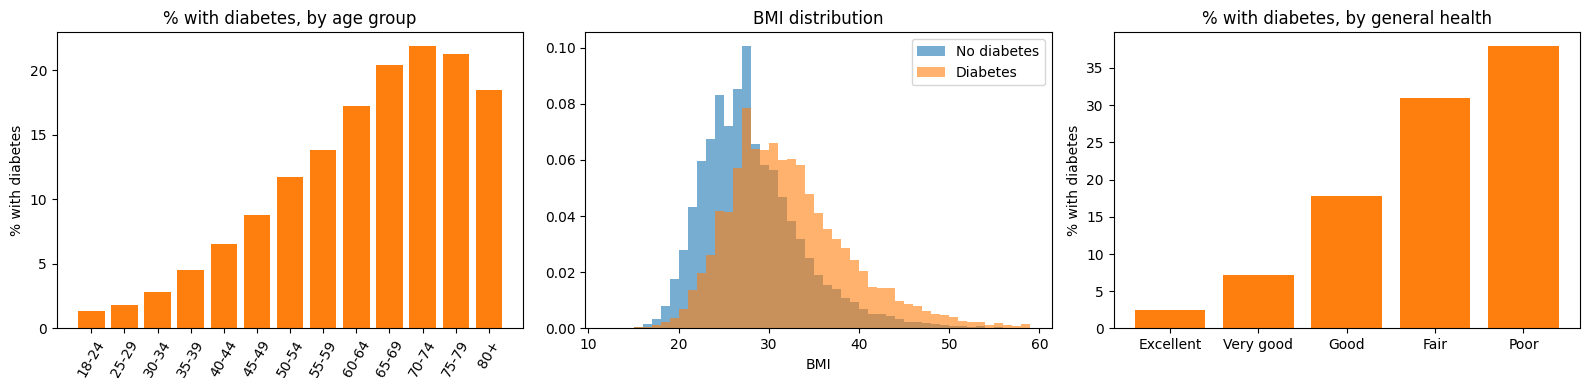

In [ ]:
# Labels for the 13 age groups, so the chart is readable
AGE_LABELS = {1: '18-24', 2: '25-29', 3: '30-34', 4: '35-39', 5: '40-44', 6: '45-49',
              7: '50-54', 8: '55-59', 9: '60-64', 10: '65-69', 11: '70-74', 12: '75-79', 13: '80+'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Chart 1: % with diabetes in each age group
by_age = df.groupby('Age')[TARGET].mean() * 100
axes[0].bar([AGE_LABELS[a] for a in by_age.index], by_age.values, color='tab:orange')
axes[0].set_title('% with diabetes, by age group')
axes[0].set_ylabel('% with diabetes')
axes[0].tick_params(axis='x', rotation=60)

# Chart 2: BMI for people with and without diabetes
axes[1].hist(df[df[TARGET] == 0]['BMI'], bins=range(12, 60), alpha=0.6, density=True, label='No diabetes')
axes[1].hist(df[df[TARGET] == 1]['BMI'], bins=range(12, 60), alpha=0.6, density=True, label='Diabetes')
axes[1].set_title('BMI distribution')
axes[1].set_xlabel('BMI')
axes[1].legend()

# Chart 3: % with diabetes by self-rated general health
by_health = df.groupby('GenHlth')[TARGET].mean() * 100
health_names = ['Excellent', 'Very good', 'Good', 'Fair', 'Poor']
axes[2].bar(health_names, by_health.values, color='tab:orange')
axes[2].set_title('% with diabetes, by general health')
axes[2].set_ylabel('% with diabetes')

plt.tight_layout()
plt.show()

In [ ]:
# For each yes/no question: % with diabetes among people who said NO vs YES
yes_no_questions = ['HighBP', 'HighChol', 'PhysActivity', 'DiffWalk', 'Smoker',
                    'HeartDiseaseorAttack', 'Stroke', 'Sex']

table = pd.DataFrame({
    'answer = 0 (no / female)': [df[df[q] == 0][TARGET].mean() * 100 for q in yes_no_questions],
    'answer = 1 (yes / male)':  [df[df[q] == 1][TARGET].mean() * 100 for q in yes_no_questions],
}, index=yes_no_questions).round(1)

print('% of people with diabetes, depending on their answer:')
table

% of people with diabetes, depending on their answer:


,answer = 0 (no / female),answer = 1 (yes / male)
HighBP,6.0,24.4
HighChol,8.0,22.0
PhysActivity,21.1,11.6
DiffWalk,10.5,30.7
Smoker,12.1,16.3
HeartDiseaseorAttack,12.0,33.0
Stroke,13.2,31.8
Sex,13.0,15.2


**What the charts show (numbers from the run above):**
- **Age:** risk climbs steadily, from about 1% at 18-24 to about 22% at 70-74, then dips a little at 80+ (about 18%). A likely reason for the dip: people with diabetes are less likely to live past 80 and answer a phone survey.
- **BMI:** the diabetes group is shifted toward higher BMI (its peak is around 30 vs around 27 for the others), but the two groups overlap a lot. BMI alone can't separate them.
- **General health:** about 2.5% of people who say 'excellent' have diabetes vs about 38% of people who say 'poor'. This is a strong signal, but partly because having diabetes *makes* people rate their health lower (cause and effect go both ways).
- **Yes/no questions:** high blood pressure (6.0% → 24.4%), high cholesterol (8.0% → 22.0%), difficulty walking (10.5% → 30.7%), heart disease (12.0% → 33.0%) and stroke (13.2% → 31.8%) each go with much higher diabetes rates. Being physically active goes with *lower* rates (21.1% if inactive vs 11.6% if active). Smoking (12.1% → 16.3%) and sex (women 13.0%, men 15.2%) make smaller differences.

No single question is enough on its own. That's why we combine them in a model.

## 3. Split the data into train, validation and test sets

We split the 253,680 people into three groups that never overlap:

| Set | Share | What it's for |
|---|---|---|
| **Train** | 60% | The model learns patterns from these people |
| **Validation** | 20% | We use these to compare models and **choose the threshold**. It's our 'practice exam' |
| **Test** | 20% | Locked away. We use it **only once, at the very end**, for the final results table. It's the 'real exam' |

**Why a separate test set?** Every time we look at results and change something, we slowly 'tune' to that data. If we did that on the test set, our final score would look better than the model really is. Keeping the test set locked gives an honest score.

**Stratified** means each set keeps the same 13.9% share of diabetics, so no set gets 'lucky' with more or fewer diabetics.

In [ ]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]   # the answers (inputs)
y = df[TARGET]     # diabetes yes/no (what we want to predict)

# Step 1: cut off 20% as the locked TEST set
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED)

# Step 2: split the remaining 80% into TRAIN (60% of all) and VALIDATION (20% of all)
# 0.25 of the remaining 80% = 20% of everyone
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=RANDOM_SEED)

for name, part_y in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:<11} {len(part_y):>7,} people   {part_y.mean():.1%} with diabetes   ({part_y.sum():,} diabetics)')

Train       152,208 people   13.9% with diabetes   (21,208 diabetics)
Validation   50,736 people   13.9% with diabetes   (7,069 diabetics)
Test         50,736 people   13.9% with diabetes   (7,069 diabetics)


### 3a. The 'twin' check: how many test people have an identical twin in the training set?

In Section 2 we found that 67% of rows are exact duplicates of another row. So many people in the test set give **exactly the same 11 answers** as someone in the training set.

This is not cheating (they are different real people), but a model could just 'remember' those answer patterns. So we mark every test person as **seen** (their pattern appears in training) or **unseen** (a brand-new pattern). At the end, we'll check the model works on *both* groups. A pharmacist will meet plenty of 'unseen' customers.

In [ ]:
# All the different answer patterns that appear in the training set
train_patterns = X_train.drop_duplicates().copy()
train_patterns['seen_in_train'] = True

# For each test person: does their exact pattern appear in training?
test_seen = X_test.merge(train_patterns, on=FEATURES, how='left')['seen_in_train']
test_seen = test_seen.notna().values   # True if a match was found, False if not

print(f'Test people whose answers match someone in training: {test_seen.mean():.1%}')
print(f'Test people with a brand-new answer pattern:         {(~test_seen).mean():.1%}  ({(~test_seen).sum():,} people)')

Test people whose answers match someone in training: 79.7%
Test people with a brand-new answer pattern:         20.3%  (10,309 people)


## 4. A helper to measure screening results

We'll score every method (baselines and models) the same way. For a screening tool, these are the numbers that matter:

| Measure | Plain meaning | Why we care |
|---|---|---|
| **Recall** (sensitivity) | Of all the real diabetics, what % did we flag? | **Most important.** A missed diabetic goes home thinking they're fine |
| **Precision** | Of the people we flagged, what % really have diabetes? | Low precision = many false alarms = wasted doctor visits |
| **False negatives (FN)** | Diabetics we told 'low risk' | The dangerous mistake |
| **False positives (FP)** | Healthy people we sent for a test | The annoying (but safe) mistake. An HbA1c test is cheap and simple |
| **Flagged %** | What share of all customers we'd send to a doctor | Tells us if the tool is practical |
| **ROC-AUC** | How well the method *ranks* people from low to high risk (0.5 = coin flip, 1.0 = perfect) | Doesn't depend on the threshold |
| **Accuracy** | % of all answers that were right | Shown only to prove it's misleading here |

In [ ]:
from sklearn.metrics import confusion_matrix, roc_auc_score

def screening_metrics(y_true, y_pred, risk_score=None):
    """Return the screening numbers for one method.
    y_true: real answers (0/1). y_pred: our flags (0/1).
    risk_score: optional number per person (higher = riskier), used for ROC-AUC."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    results = {
        'Recall':      tp / (tp + fn),
        'Precision':   tp / (tp + fp) if (tp + fp) > 0 else 0.0,   # 0 if we never flag anyone
        'False neg':   fn,
        'False pos':   fp,
        'Flagged %':   (tp + fp) / len(y_true),
        'Accuracy':    (tp + tn) / len(y_true),
    }
    if risk_score is not None:
        results['ROC-AUC'] = roc_auc_score(y_true, risk_score)
    return results

print('Helper ready.')

Helper ready.


## 5. Baseline 1: always say 'no diabetes'

A **baseline** is the simplest possible method. Any real model must beat it, or it's useless.

Baseline 1 is the laziest tool imaginable: it tells **every** customer 'low risk'. We score it on the **validation** set (the test set stays locked until the final table).

In [ ]:
# Predict 0 ('no diabetes') for every person in the validation set
baseline1_pred = np.zeros(len(y_val), dtype=int)
# Every person gets the same risk score, so the ranking is no better than a coin flip
baseline1_score = np.zeros(len(y_val))

b1 = screening_metrics(y_val, baseline1_pred, baseline1_score)
for measure, value in b1.items():
    print(f'{measure:<10} {value:.3f}' if isinstance(value, float) else f'{measure:<10} {value:,}')

Recall     0.000
Precision  0.000
False neg  7,069
False pos  0
Flagged %  0.000
Accuracy   0.861
ROC-AUC    0.500


**Why accuracy is misleading here:** Baseline 1 scores about **86% accuracy**, which sounds good. But its **recall is 0**: it catches **zero** diabetics, and every one of them is a false negative. It's a tool that never does its one job.

This happens because only 14% of people have diabetes, so saying 'no' to everyone is right 86% of the time. **From now on we judge methods by recall, precision and the counts of each mistake, not accuracy.**